# Example of the aitlas toolbox in the context of image classification

The data consists of a single pixel value for each S2 band, for each time step (365 days). To each S2 time series is associated a crop type label.

## Import the required packages

In [ ]:
from aitlas.datasets import CropTypeKenyaDataset
from aitlas.utils import image_loader
from aitlas.models import LSTM
from aitlas.transforms import MinMaxNormTranspose, ResizeToTensor

## Inspect the data

In [85]:
dataset_config = {
    "data_dir" : "/home/dragik/data/FAIR_EO/crop_type_kenya",
}
dataset = CropTypeKenyaDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")

Total number of patches: 5746


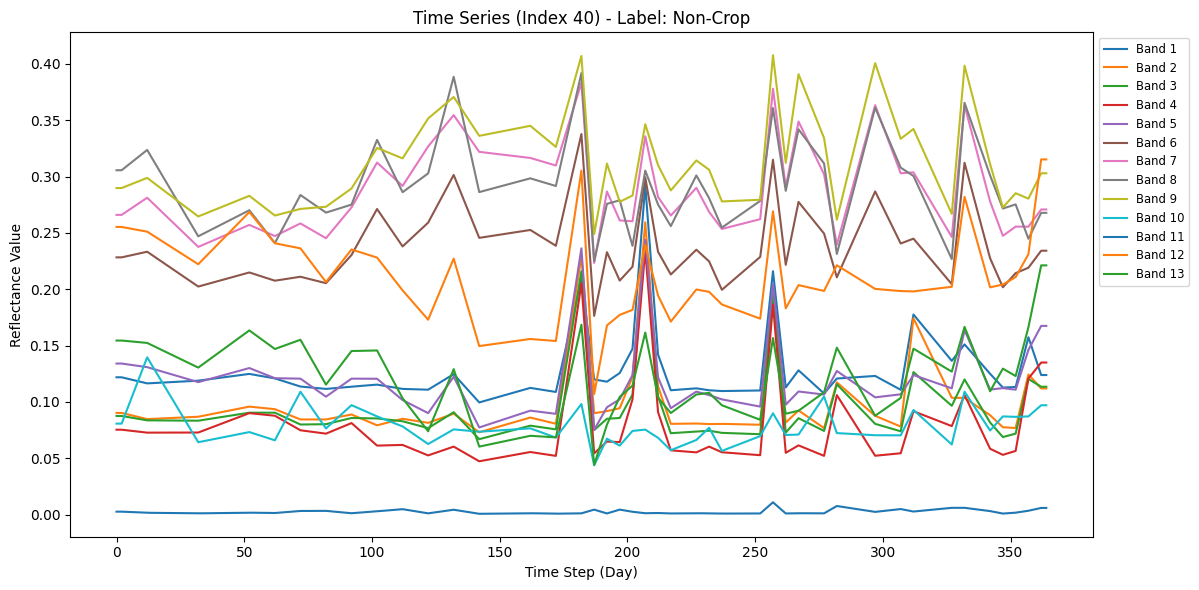

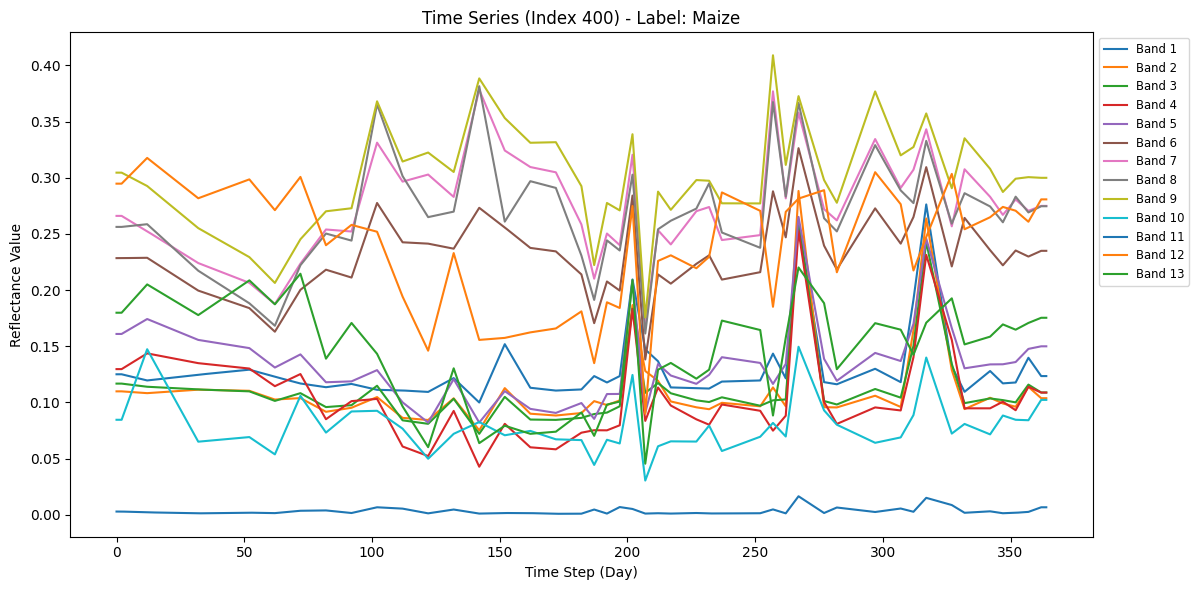

In [86]:
dataset.show_timeseries(index=40)
dataset.show_timeseries(index=400);

In [149]:
dataset.data_distribution_table()

,Label,Count
0,Banana,209
1,Beans,265
2,Cassava,512
3,Groundnut,138
4,Maize,2598
5,Non-Crop,654
6,Other,490
7,Sugar Cane,539
8,Sweet Potatoes,333


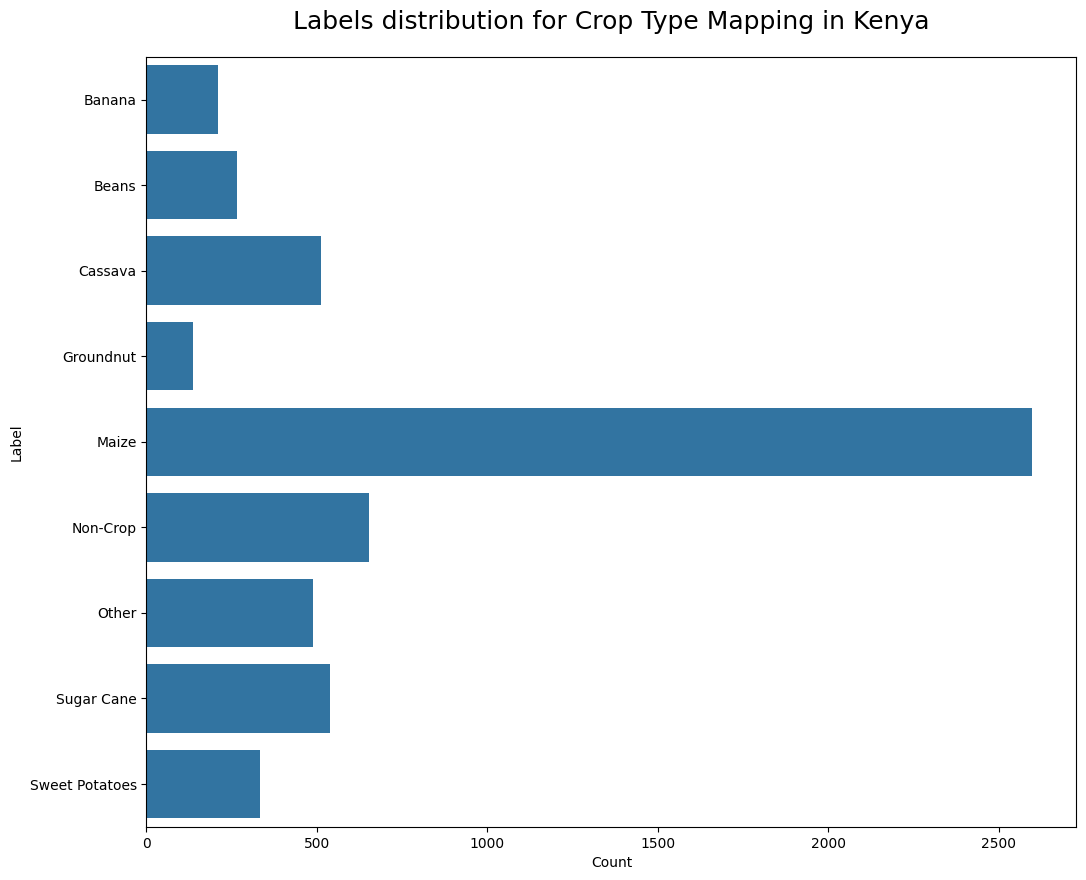

In [150]:
dataset.data_distribution_barchart();

## Load training data ##

In [ ]:
train_dataset_config = {
    "batch_size": 16,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "/home/dragik/data/FAIR_EO/crop_type_kenya",
    "mode":"train",
}
train_dataset = CropTypeKenyaDataset(train_dataset_config)

test_dataset_config = {
    "batch_size": 16,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "/home/dragik/data/FAIR_EO/crop_type_kenya",
    "mode":"test",
}
test_dataset = CropTypeKenyaDataset(test_dataset_config)

print(len(train_dataset),len(test_dataset))

4596 1150


## Create the model ##

In [92]:
epochs = 50
model_directory = "/home/dragik/data/FAIR_EO/experiments/crop_type_kenya/"
model_config = {
                "input_dim": 13,
                "num_classes": 9,
                "learning_rate": 0.00988,
                "weight_decay" : 0.000000526,
                "num_layers" : 4,
                "hidden_dims" : 128,
                "dropout" : 0.5713,
                "metrics":["accuracy","f1_score", "kappa"]
            }
model = LSTM(model_config)
model.prepare()

## Start the training

In [93]:
model.train_and_evaluate_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    val_dataset=test_dataset,
    run_id='1',
)

2025-10-15 09:15:11,267 INFO Starting training.
training: 100%|██████████| 288/288 [00:08<00:00, 33.19it/s]
2025-10-15 09:15:19,954 INFO epoch: 1, time: 8, loss:  1.94772
testing on train set: 100%|██████████| 288/288 [00:08<00:00, 32.87it/s]
2025-10-15 09:15:28,775 INFO Accuracy:0.44778067885117495, F1_score Micro:0.44778067885117445, F1_score Macro:0.06873058811742305, F1_score Weighted:0.27698606464554176, F1_score per Class:[0.         0.         0.         0.         0.61857529 0.
 0.         0.         0.        ], Kappa metric:tensor(0., dtype=torch.float64)
testing on validation set: 100%|██████████| 72/72 [00:02<00:00, 28.72it/s]
2025-10-15 09:15:31,291 INFO Accuracy:0.47304347826086957, F1_score Micro:0.47304347826086907, F1_score Macro:0.07136298045388949, F1_score Weighted:0.30382013243673295, F1_score per Class:[0.         0.         0.         0.         0.64226682 0.
 0.         0.         0.        ], Kappa metric:tensor(0., dtype=torch.float64)
training: 100%|█████████

1.237776348651026